In [1]:
#1
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ==============================
# Core Libraries 2
# ==============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ==============================
# Scikit-learn: Preprocessing
# ==============================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ==============================
# Scikit-learn: Models
# ==============================
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans

# ==============================
# Scikit-learn: Metrics
# ==============================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

# ==============================
# Global Settings
# ==============================
sns.set(style="whitegrid")
POS_LABEL = "p"          # poisonous
NEG_LABEL = "e"          # edible
target_col = "class"     # target column


In [ ]:
#3


PROJECT_DIR = "/content/drive/MyDrive/cse422 project"
DATA_DIR = os.path.join(PROJECT_DIR, "data")

print("DATA_DIR:", DATA_DIR)
print("Files in data/:")
print(os.listdir(DATA_DIR))


DATA_DIR: /content/drive/MyDrive/cse422 project/data
Files in data/:
['mushroom_dataset.csv']


In [ ]:
#4


PROJECT_DIR = "/content/drive/MyDrive/cse422 project"

DATA_PATH  = os.path.join(PROJECT_DIR, "data", "mushroom_dataset.csv")
FIG_DIR    = os.path.join(PROJECT_DIR, "figures")
REPORT_DIR = os.path.join(PROJECT_DIR, "report")

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

print("DATA_PATH:", DATA_PATH)
print("FIG_DIR:", FIG_DIR)
print("REPORT_DIR:", REPORT_DIR)


DATA_PATH: /content/drive/MyDrive/cse422 project/data/mushroom_dataset.csv
FIG_DIR: /content/drive/MyDrive/cse422 project/figures
REPORT_DIR: /content/drive/MyDrive/cse422 project/report


In [ ]:
#5
df = pd.read_csv(DATA_PATH, sep=';')
df_copy = df.copy()

print("Shape:", df.shape)
df.head()


Shape: (61069, 21)


,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,...,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,p,15.26,x,g,o,f,e,NaN,w,16.95,...,s,y,w,u,w,t,g,NaN,d,w
1,p,16.60,x,g,o,f,e,NaN,w,17.99,...,s,y,w,u,w,t,g,NaN,d,u
2,p,14.07,x,g,o,f,e,NaN,w,17.80,...,s,y,w,u,w,t,g,NaN,d,w
3,p,14.17,f,h,e,f,e,NaN,w,15.77,...,s,y,w,u,w,t,p,NaN,d,w
4,p,14.64,x,h,o,f,e,NaN,w,16.53,...,s,y,w,u,w,t,p,NaN,d,w


In [ ]:
#6

X = df.drop(columns=[target_col])
y = df[target_col]

print("Total data points (rows):", df.shape[0])
print("Total columns:", df.shape[1])
print("Total input features:", X.shape[1])
print("Target classes:", sorted(y.unique()))

num_cols = X.select_dtypes(include=["int64","float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()

print("\nNumeric features:", len(num_cols))
print("Categorical features:", len(cat_cols))

print("\nClass distribution:")
print(y.value_counts(dropna=False))

print("\nMissing values (top 10 columns):")
print(df.isna().sum().sort_values(ascending=False).head(10))


Total data points (rows): 61069
Total columns: 21
Total input features: 20
Target classes: ['e', 'p']

Numeric features: 3
Categorical features: 17

Class distribution:
class
p    33888
e    27181
Name: count, dtype: int64

Missing values (top 10 columns):
veil-type            57892
spore-print-color    54715
veil-color           53656
stem-root            51538
stem-surface         38124
gill-spacing         25063
cap-surface          14120
gill-attachment       9884
ring-type             2471
cap-color                0
dtype: int64


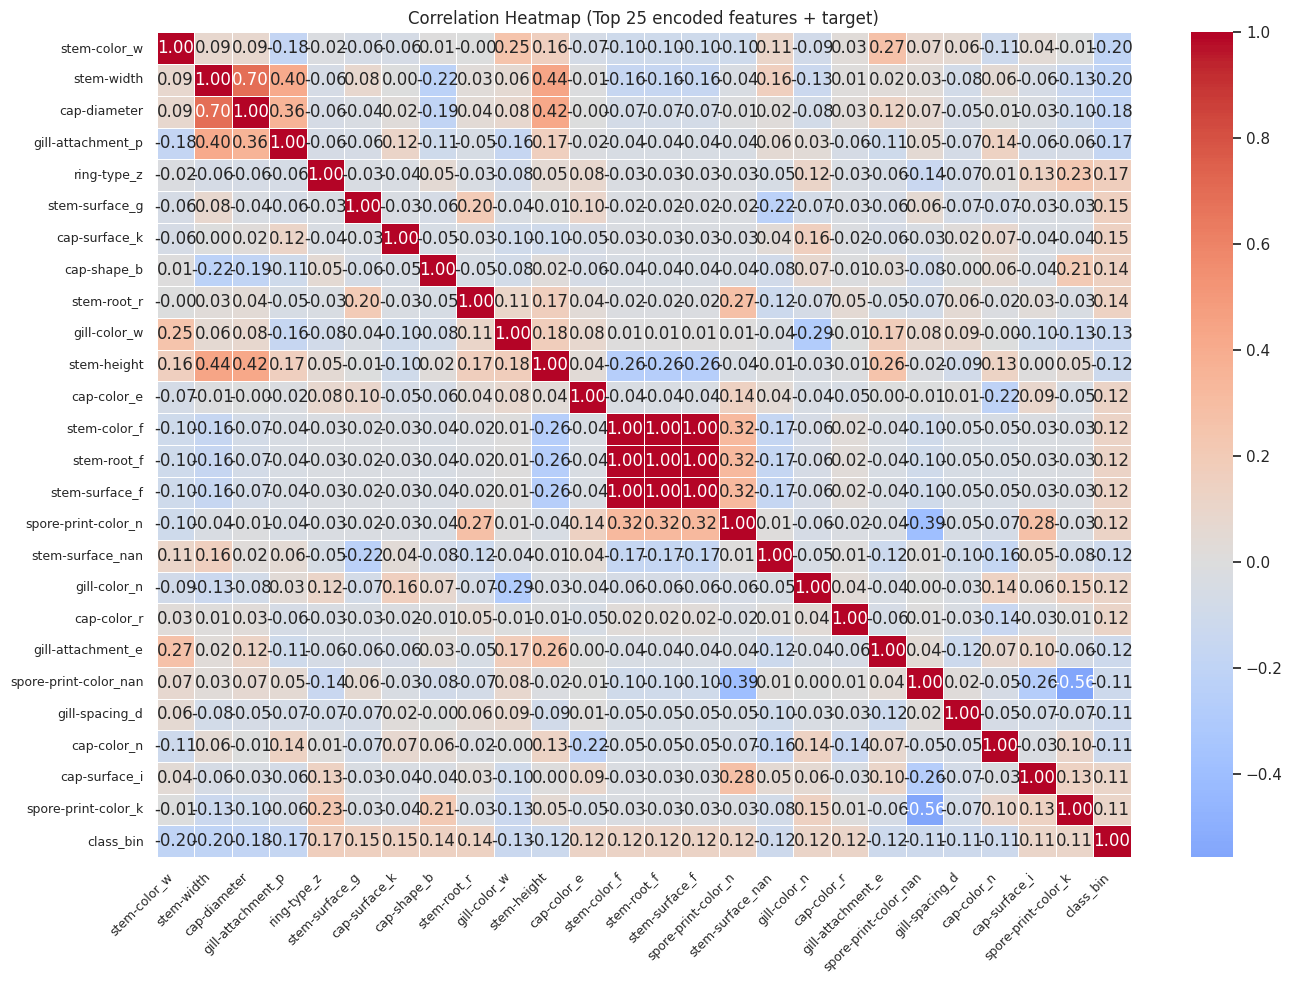

Top correlations with target (class_bin):
stem-color_w        -0.199979
stem-width          -0.197368
cap-diameter        -0.181139
gill-attachment_p   -0.173232
ring-type_z          0.169757
stem-surface_g       0.154504
cap-surface_k        0.145987
cap-shape_b          0.144631
stem-root_r          0.137783
gill-color_w        -0.133578
Name: class_bin, dtype: float64


In [ ]:
#7


# -----------------------------
# Correlation (Top 25 encoded features + target)
# -----------------------------

X = df.drop(columns=[target_col])
y = df[target_col]

# Map target to numeric (needed for correlation)
# e = 0, p = 1
y_bin = y.map({'e': 0, 'p': 1})

# One-hot encode categorical features (keeps missing as its own category)
X_oh = pd.get_dummies(X, dummy_na=True)

# Combine features + target
corr_df = X_oh.copy()
corr_df["class_bin"] = y_bin

# Correlation with target only
corr_with_target = corr_df.corr()["class_bin"].drop("class_bin")

# Take top 25 features by absolute correlation (for a readable heatmap)
top_feats = corr_with_target.abs().sort_values(ascending=False).head(25).index.tolist()

# Build a small correlation matrix: top 25 features + target
heatmap_cols = top_feats + ["class_bin"]
corr_small = corr_df[heatmap_cols].corr()

# Plot heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_small,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap (Top 25 encoded features + target)")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()


print("Top correlations with target (class_bin):")
print(corr_with_target.sort_values(key=lambda s: s.abs(), ascending=False).head(10))


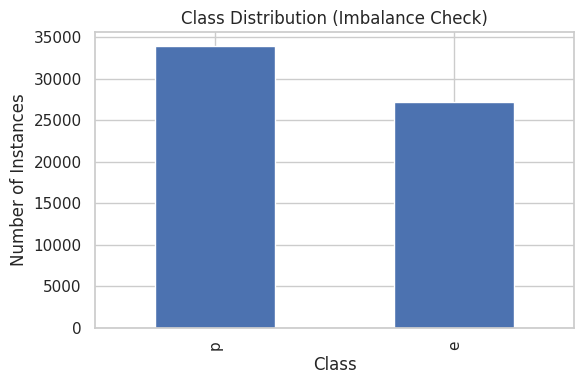

class
p    33888
e    27181
Name: count, dtype: int64


In [ ]:
#8


plt.figure(figsize=(6,4))
df["class"].value_counts().plot(kind="bar")
plt.title("Class Distribution (Imbalance Check)")
plt.xlabel("Class")
plt.ylabel("Number of Instances")
plt.tight_layout()
plt.show()

print(df["class"].value_counts())


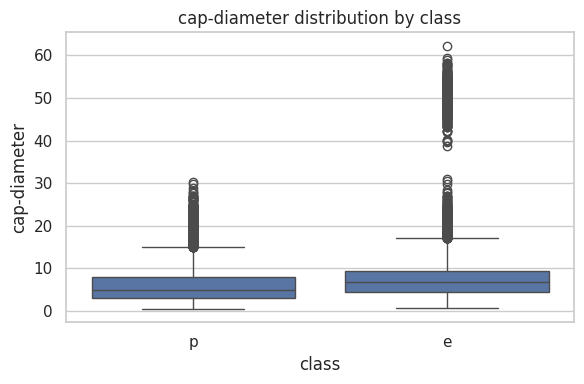

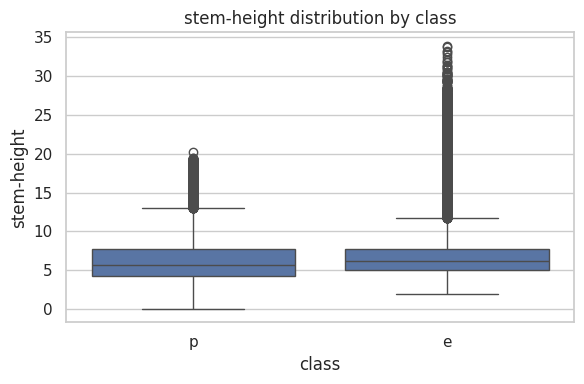

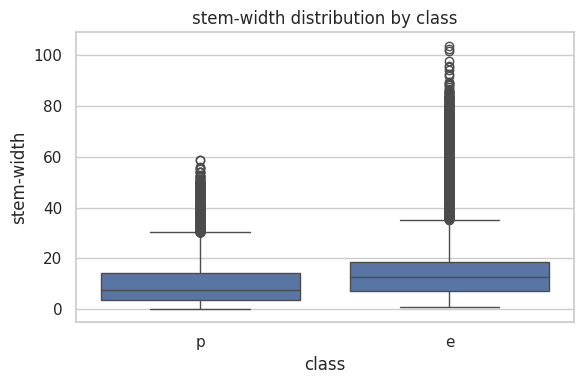

       cap-diameter  stem-height  stem-width
class                                       
e          7.798696     7.039077   14.361084
p          5.879763     6.214554   10.375463


In [ ]:
#9


num_features = ["cap-diameter", "stem-height", "stem-width"]

for col in num_features:
    plt.figure(figsize=(6,4))
    sns.boxplot(data=df, x="class", y=col)
    plt.title(f"{col} distribution by class")
    plt.tight_layout()
    plt.show()

print(df.groupby("class")[num_features].mean())


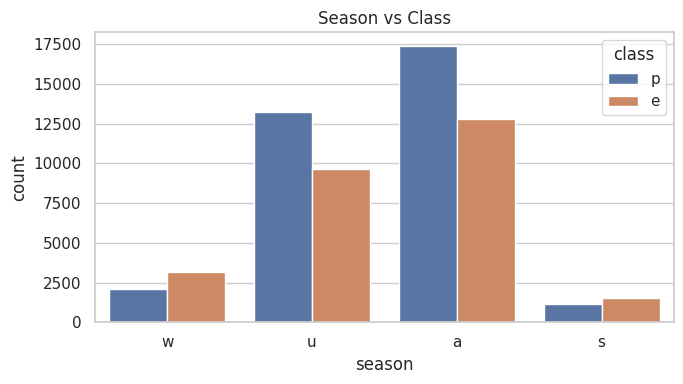

class          e         p
season                    
a       0.423667  0.576333
s       0.569490  0.430510
u       0.421303  0.578697
w       0.606797  0.393203


In [ ]:
#10

plt.figure(figsize=(7,4))
sns.countplot(data=df, x="season", hue="class")
plt.title("Season vs Class")
plt.tight_layout()
plt.show()


season_prop = pd.crosstab(df["season"], df["class"], normalize="index")
print(season_prop)


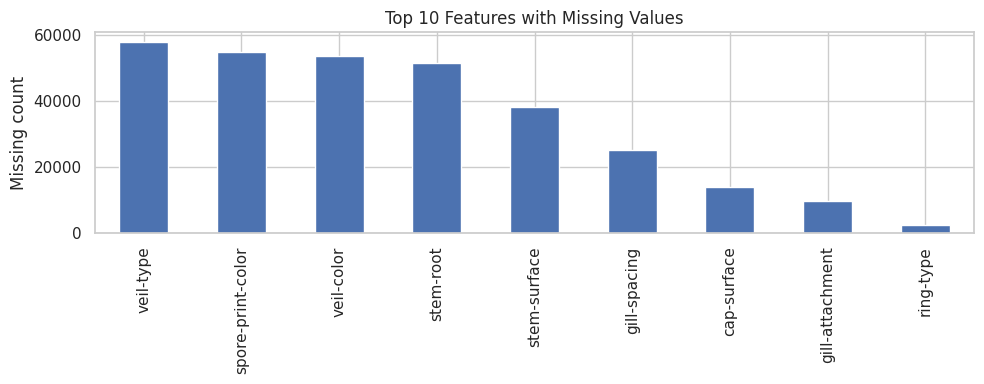

veil-type            57892
spore-print-color    54715
veil-color           53656
stem-root            51538
stem-surface         38124
gill-spacing         25063
cap-surface          14120
gill-attachment       9884
ring-type             2471
cap-color                0
dtype: int64


In [ ]:
#11
missing = df.isna().sum().sort_values(ascending=False)
plt.figure(figsize=(10,4))
missing[missing > 0].head(10).plot(kind="bar")
plt.title("Top 10 Features with Missing Values")
plt.ylabel("Missing count")
plt.tight_layout()
plt.show()

print(missing.head(10))


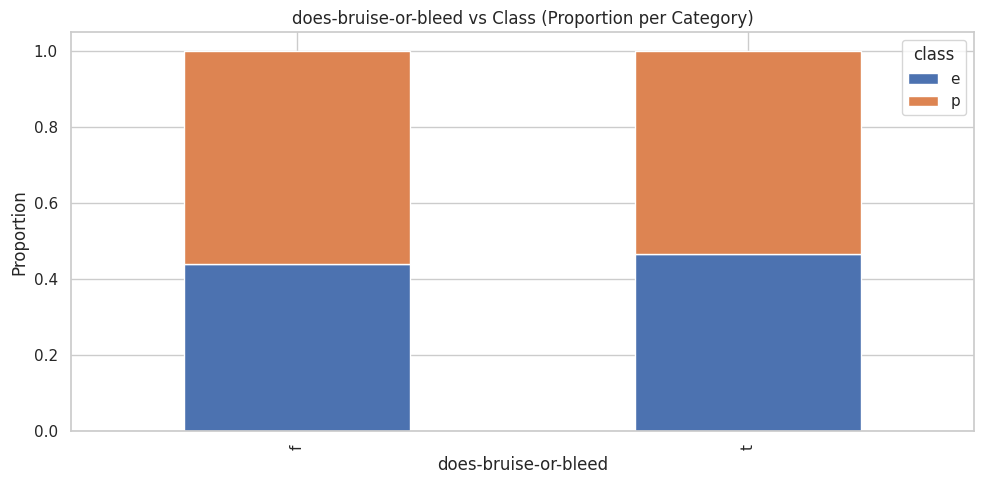

=== Counts (by category x class) ===
class                     e      p
does-bruise-or-bleed              
f                     22239  28240
t                      4942   5648

=== Poisonous rate per category (p %) ===
does-bruise-or-bleed
f    55.94
t    53.33
dtype: float64

=== Quick takeaway ===
Highest poisonous share: f -> 55.94% poisonous
Lowest poisonous share:  t -> 53.33% poisonous

Saved figure to: /content/drive/MyDrive/cse422 project/figures/eda_does-bruise-or-bleed_vs_class_stacked.png


In [ ]:
#12


candidate_features = [
    "does-bruise-or-bleed",
    "has-ring",
    "ring-type",
    "gill-attachment",
    "gill-spacing",
    "gill-color",
    "cap-shape",
    "cap-surface",
    "cap-color",
    "stem-root",
    "stem-surface",
    "stem-color",
    "veil-type",
    "veil-color",
    "spore-print-color",
    "habitat",
    "season",
]

FEATURE = next((c for c in candidate_features if c in df.columns), None)
if FEATURE is None:
    raise ValueError("No candidate categorical feature found in df. Check df.columns.")


ct_counts = pd.crosstab(df[FEATURE], df["class"])
ct_props  = pd.crosstab(df[FEATURE], df["class"], normalize="index")

# --- Plot: stacked bar chart of class proportions ---
ax = ct_props.plot(kind="bar", stacked=True, figsize=(10, 5))
ax.set_title(f"{FEATURE} vs Class (Proportion per Category)")
ax.set_xlabel(FEATURE)
ax.set_ylabel("Proportion")
ax.legend(title="class", loc="upper right")
plt.tight_layout()
plt.show()


# Poisonous rate per category (class 'p')
p_rate = (ct_counts.get("p", 0) / ct_counts.sum(axis=1)).sort_values(ascending=False)

best_poison_cat = p_rate.index[0]
best_poison_val = float(p_rate.iloc[0]) * 100

best_edible_cat = p_rate.index[-1]
best_edible_val = float(p_rate.iloc[-1]) * 100

print("=== Counts (by category x class) ===")
print(ct_counts)

print("\n=== Poisonous rate per category (p %) ===")
print((p_rate * 100).round(2))

print("\n=== Quick takeaway ===")
print(f"Highest poisonous share: {best_poison_cat} -> {best_poison_val:.2f}% poisonous")
print(f"Lowest poisonous share:  {best_edible_cat} -> {best_edible_val:.2f}% poisonous")


try:
    import os
    if "FIG_DIR" in globals():
        outpath = os.path.join(FIG_DIR, f"eda_{FEATURE}_vs_class_stacked.png")
        ax.figure.savefig(outpath, dpi=200, bbox_inches="tight")
        print("\nSaved figure to:", outpath)
except Exception as e:
    print("Save skipped:", e)


In [ ]:
#13
# 2) Handle missing values

df_prep = df0.copy()

num_cols = df_prep.drop(columns=[target_col]).select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = df_prep.drop(columns=[target_col]).select_dtypes(include=["object"]).columns.tolist()

print("\nNumeric columns:", num_cols)
print("Categorical columns (showing first 10):", cat_cols[:10], "..." if len(cat_cols) > 10 else "")

before_total_missing = int(df_prep.isna().sum().sum())
print("\nTotal missing values BEFORE cleaning:", before_total_missing)

for col in num_cols:
    df_prep[col] = df_prep[col].fillna(df_prep[col].median())

for col in cat_cols:
    df_prep[col] = df_prep[col].fillna("missing")

after_total_missing = int(df_prep.isna().sum().sum())
print("Total missing values AFTER cleaning:", after_total_missing)


cols_to_preview = (num_cols + cat_cols[:6])  # keep it readable
print("\nPreview (after cleaning):")
display(df_prep[cols_to_preview + [target_col]].head(8))


Numeric columns: ['cap-diameter', 'stem-height', 'stem-width']
Categorical columns (showing first 10): ['cap-shape', 'cap-surface', 'cap-color', 'does-bruise-or-bleed', 'gill-attachment', 'gill-spacing', 'gill-color', 'stem-root', 'stem-surface', 'stem-color'] ...

Total missing values BEFORE cleaning: 307463
Total missing values AFTER cleaning: 0

Preview (after cleaning):


,cap-diameter,stem-height,stem-width,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,class
0,15.26,16.95,17.09,x,g,o,f,e,missing,p
1,16.60,17.99,18.19,x,g,o,f,e,missing,p
2,14.07,17.80,17.74,x,g,o,f,e,missing,p
3,14.17,15.77,15.98,f,h,e,f,e,missing,p
4,14.64,16.53,17.20,x,h,o,f,e,missing,p
5,15.34,17.84,18.79,x,g,o,f,e,missing,p
6,14.85,17.71,16.89,f,h,o,f,e,missing,p
7,14.86,17.03,17.44,x,h,e,f,e,missing,p


In [ ]:
#14
# 3) One-hot encoding (categorical -> numeric)
# ----------------------------
X = df_prep.drop(columns=[target_col])
y = df_prep[target_col]

print("\nShape before encoding:", X.shape)

X_encoded = pd.get_dummies(X, columns=cat_cols, dummy_na=False)  # dummy_na False since we used "missing"
print("Shape after encoding:", X_encoded.shape)


print("\nEncoded feature preview (first 8 rows, first 12 columns):")
display(X_encoded.iloc[:8, :12])



Shape before encoding: (61069, 20)
Shape after encoding: (61069, 128)

Encoded feature preview (first 8 rows, first 12 columns):


,cap-diameter,stem-height,stem-width,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_o,cap-shape_p,cap-shape_s,cap-shape_x,cap-surface_d,cap-surface_e
0,15.26,16.95,17.09,False,False,False,False,False,False,True,False,False
1,16.60,17.99,18.19,False,False,False,False,False,False,True,False,False
2,14.07,17.80,17.74,False,False,False,False,False,False,True,False,False
3,14.17,15.77,15.98,False,False,True,False,False,False,False,False,False
4,14.64,16.53,17.20,False,False,False,False,False,False,True,False,False
5,15.34,17.84,18.79,False,False,False,False,False,False,True,False,False
6,14.85,17.71,16.89,False,False,True,False,False,False,False,False,False
7,14.86,17.03,17.44,False,False,False,False,False,False,True,False,False


In [ ]:
#15
#train/test split


x_train, x_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", x_train.shape)
print("Test shape :", x_test.shape)
print("\nTrain class distribution:\n", y_train.value_counts())
print("\nTest class distribution:\n", y_test.value_counts())


Train shape: (48855, 128)
Test shape : (12214, 128)

Train class distribution:
 class
p    27110
e    21745
Name: count, dtype: int64

Test class distribution:
 class
p    6778
e    5436
Name: count, dtype: int64


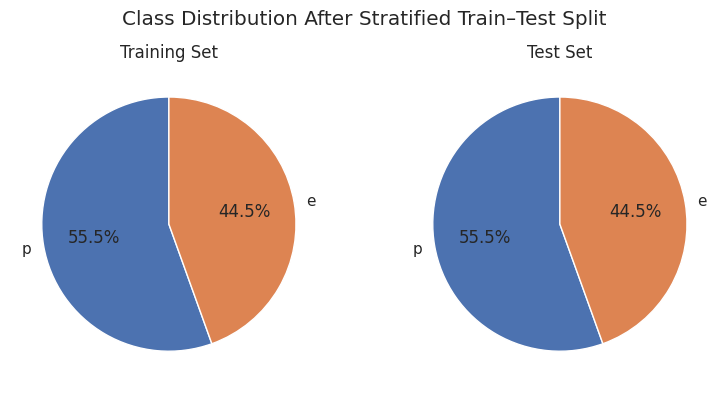

In [ ]:
# ------------------------------------
# Class distribution after train-test split 15.1
# ------------------------------------
train_counts = y_train.value_counts()
test_counts = y_test.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Training set pie
axes[0].pie(
    train_counts,
    labels=train_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("Training Set")

# Test set pie
axes[1].pie(
    test_counts,
    labels=test_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Test Set")

plt.suptitle("Class Distribution After Stratified Train–Test Split")
plt.tight_layout()
plt.show()


In [ ]:
#scaling set up  #16


# BEFORE feature scaling
X_train_before = x_train.copy()
X_test_before  = x_test.copy()

# AFTER feature scaling
scaler = StandardScaler()
X_train_after = scaler.fit_transform(x_train)
X_test_after  = scaler.transform(x_test)

print("Scaling completed.")


Scaling completed.


In [ ]:
#model definitons 17
#creation

models = {
    "KNN (k=13)": KNeighborsClassifier(n_neighbors=13),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Neural Network": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        max_iter=300,
        random_state=42
    )
}

print("Models initialized.")


Models initialized.


In [ ]:
#18


POS_LABEL = "p"

def run_full_evaluation(Xtr, Xte, ytr, yte, case_name):
    print(f"\n==============================")
    print(f"RESULTS: {case_name}")
    print(f"==============================")

    rows = []

    # ---------- Classification report + Confusion Matrix ----------
    for name, model in models.items():
        model.fit(Xtr, ytr) #training
        y_pred = model.predict(Xte) #testing

        print(f"\nModel: {name}")
        print(classification_report(yte, y_pred, zero_division=0))

        cm = confusion_matrix(yte, y_pred, labels=["e", "p"])
        disp = ConfusionMatrixDisplay(cm, display_labels=["e", "p"])

        plt.figure(figsize=(4,4))
        disp.plot(values_format="d", cmap="Blues")
        plt.title(f"Confusion Matrix – {name} ({case_name})")
        plt.tight_layout()
        plt.show()

        rows.append({
            "Model": name,
            "Accuracy": accuracy_score(yte, y_pred),
            "Precision": precision_score(yte, y_pred, pos_label=POS_LABEL, zero_division=0),
            "Recall": recall_score(yte, y_pred, pos_label=POS_LABEL, zero_division=0)
        })

    metrics_df = pd.DataFrame(rows)

    # ---------- Accuracy Bar Chart ----------
    plt.figure(figsize=(6,4))
    plt.bar(metrics_df["Model"], metrics_df["Accuracy"])
    plt.ylim(0.9, 1.02)
    plt.ylabel("Accuracy")
    plt.title(f"Accuracy Comparison ({case_name})")

    for i, v in enumerate(metrics_df["Accuracy"]):
        plt.text(i, v + 0.002, f"{v:.4f}", ha="center")

    plt.tight_layout()
    plt.show()

    # ---------- Precision / Recall Bar Chart ----------
    x = np.arange(len(metrics_df))
    width = 0.35

    plt.figure(figsize=(7,4))
    plt.bar(x - width/2, metrics_df["Precision"], width, label="Precision")
    plt.bar(x + width/2, metrics_df["Recall"], width, label="Recall")

    plt.xticks(x, metrics_df["Model"])
    plt.ylim(0.9, 1.02)
    plt.title(f"Precision & Recall ({case_name})")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # ---------- ROC Curve ----------
    plt.figure(figsize=(6,5))
    for name, model in models.items():
        if hasattr(model, "predict_proba"):
            probs = model.predict_proba(Xte)
            pos_index = list(model.classes_).index(POS_LABEL)
            y_prob = probs[:, pos_index]

            y_bin = (yte == POS_LABEL).astype(int)
            fpr, tpr, _ = roc_curve(y_bin, y_prob)
            auc_score = auc(fpr, tpr)

            plt.plot(fpr, tpr, label=f"{name} (AUC={auc_score:.4f})")

    plt.plot([0,1], [0,1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve ({case_name})")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return metrics_df



RESULTS: Before Feature Scaling

Model: KNN (k=13)
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6778

    accuracy                           1.00     12214
   macro avg       1.00      1.00      1.00     12214
weighted avg       1.00      1.00      1.00     12214



<Figure size 400x400 with 0 Axes>

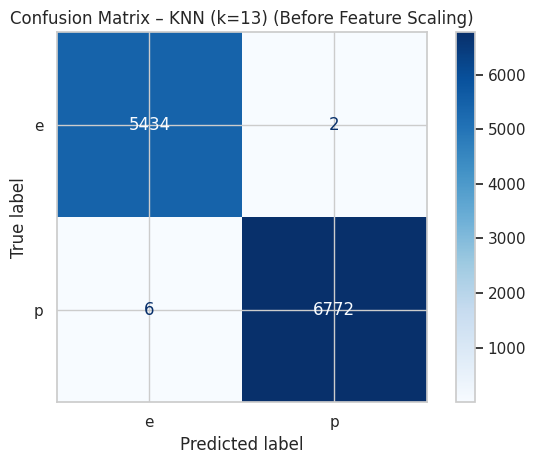


Model: Decision Tree
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6778

    accuracy                           1.00     12214
   macro avg       1.00      1.00      1.00     12214
weighted avg       1.00      1.00      1.00     12214



<Figure size 400x400 with 0 Axes>

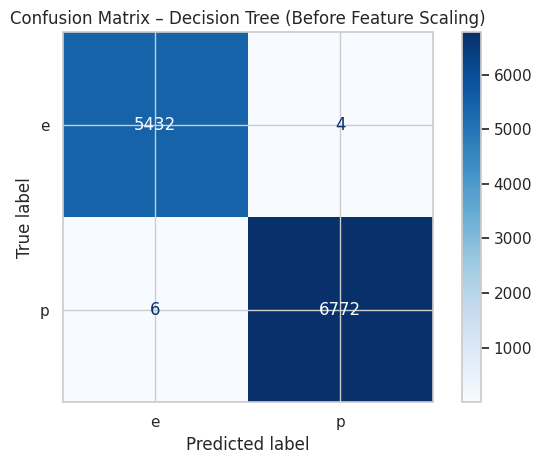


Model: Neural Network
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6778

    accuracy                           1.00     12214
   macro avg       1.00      1.00      1.00     12214
weighted avg       1.00      1.00      1.00     12214



<Figure size 400x400 with 0 Axes>

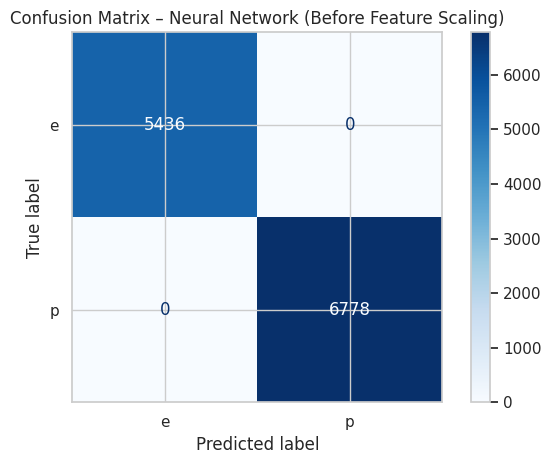

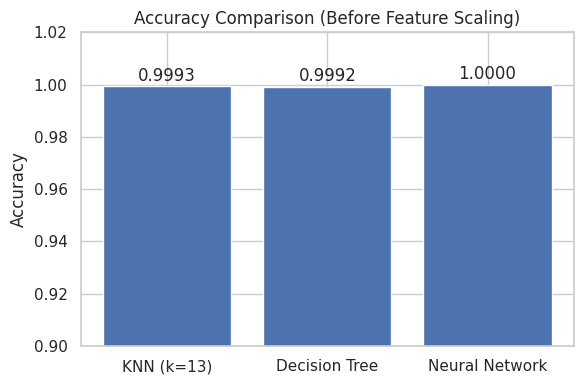

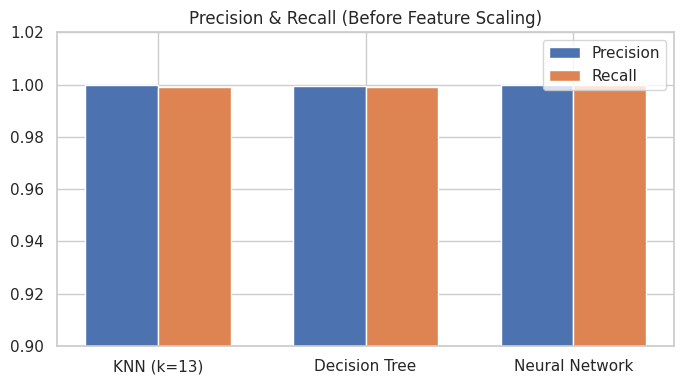

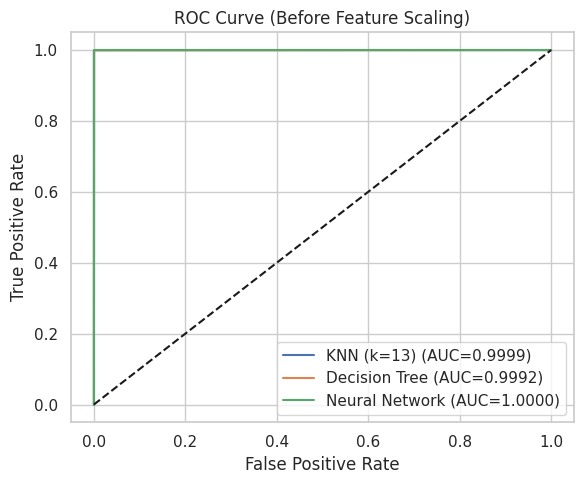

,Model,Accuracy,Precision,Recall
0,KNN (k=13),0.999345,0.999705,0.999115
1,Decision Tree,0.999181,0.999410,0.999115
2,Neural Network,1.000000,1.000000,1.000000


In [ ]:
metrics_before = run_full_evaluation(
    X_train_before, X_test_before, #19
    y_train, y_test,
    "Before Feature Scaling"
)

metrics_before



RESULTS: After Feature Scaling

Model: KNN (k=13)
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6778

    accuracy                           1.00     12214
   macro avg       1.00      1.00      1.00     12214
weighted avg       1.00      1.00      1.00     12214



<Figure size 400x400 with 0 Axes>

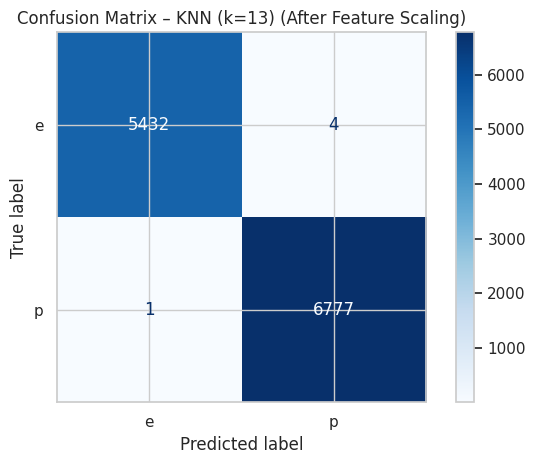


Model: Decision Tree
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6778

    accuracy                           1.00     12214
   macro avg       1.00      1.00      1.00     12214
weighted avg       1.00      1.00      1.00     12214



<Figure size 400x400 with 0 Axes>

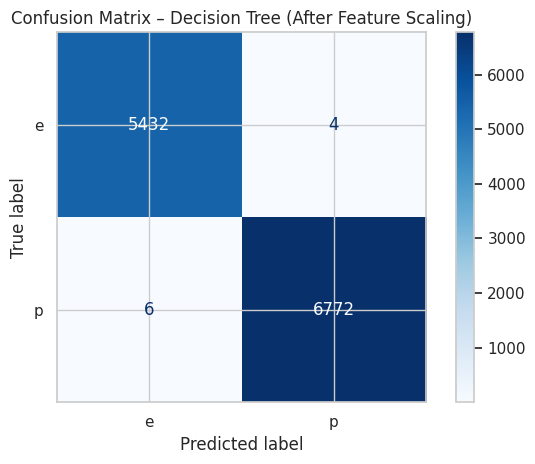


Model: Neural Network
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6778

    accuracy                           1.00     12214
   macro avg       1.00      1.00      1.00     12214
weighted avg       1.00      1.00      1.00     12214



<Figure size 400x400 with 0 Axes>

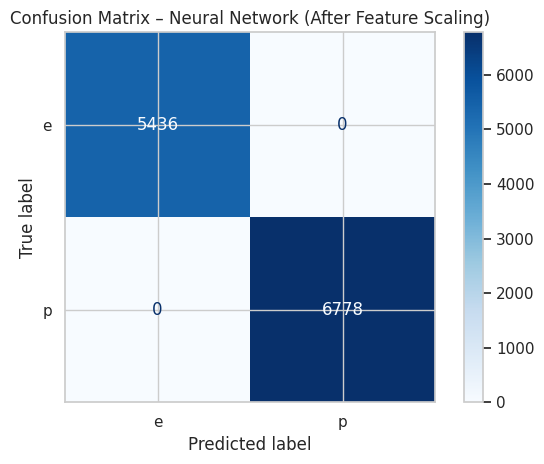

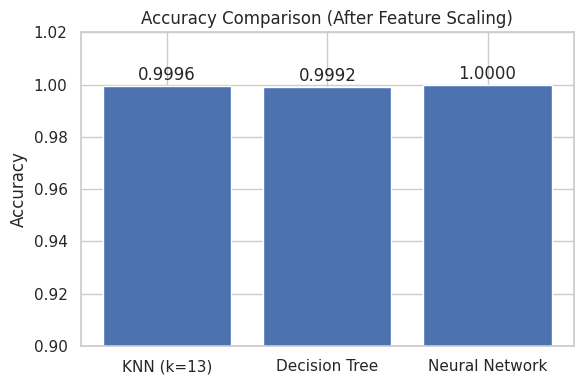

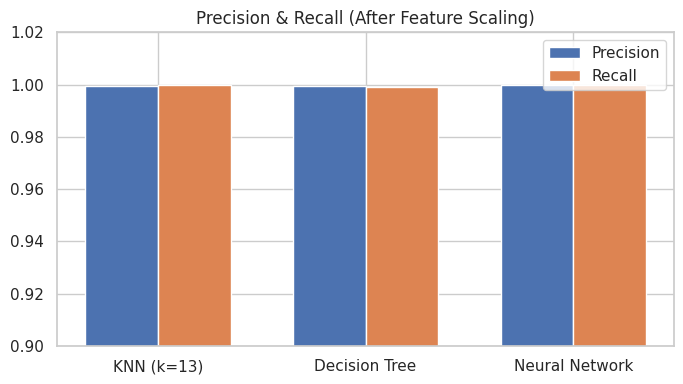

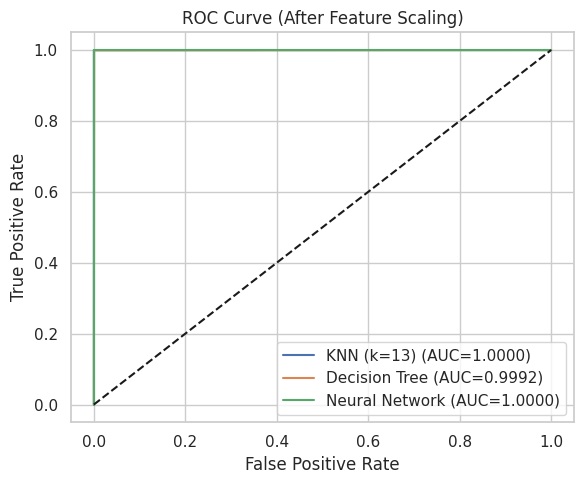

,Model,Accuracy,Precision,Recall
0,KNN (k=13),0.999591,0.99941,0.999852
1,Decision Tree,0.999181,0.99941,0.999115
2,Neural Network,1.000000,1.00000,1.000000


In [ ]:
metrics_after = run_full_evaluation( #20
    X_train_after, X_test_after,
    y_train, y_test,
    "After Feature Scaling"
)

metrics_after


In [ ]:
#PCA for dimensionailty reduction 21
# Reduce features to 2D using PCA for visualization
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_after)  # use SCALED features

print("Original feature size:", X_train_after.shape)
print("Reduced feature size:", X_train_pca.shape)

Original feature size: (48855, 128)
Reduced feature size: (48855, 2)


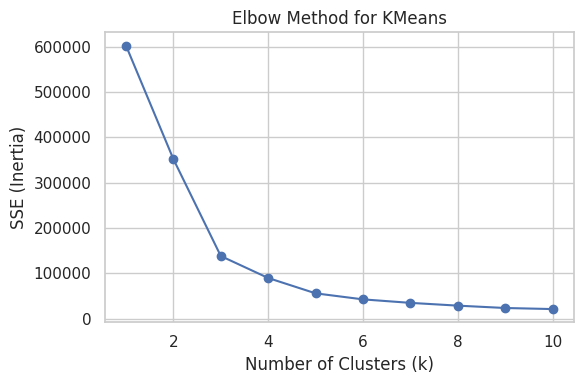

In [ ]:
# Elbow Method to find optimal number of clusters 22
SSE = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_train_pca)
    SSE.append(kmeans.inertia_)

plt.figure(figsize=(6,4))
plt.plot(k_range, SSE, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("SSE (Inertia)")
plt.title("Elbow Method for KMeans")
plt.tight_layout()
plt.show()

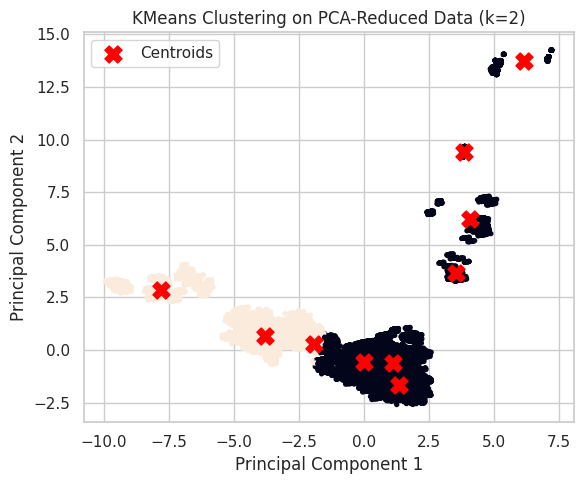

In [ ]:
plt.figure(figsize=(6,5))#23
plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=cluster_labels,
    s=8
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=150,
    marker="X",
    c="red",
    label="Centroids"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("KMeans Clustering on PCA-Reduced Data (k=2)")
plt.legend()
plt.tight_layout()
plt.show()